# TP4. Matrices et systèmes linéaires

Carnet de travail. L'énoncé complet, avec les corrigés, est sur le site :
https://cours.gclab.fr/outils-fondamentaux/tp4-matrices-gauss/

Exécutez une cellule avec Maj+Entrée. **Pensez à télécharger ce carnet avant de partir** : menu File, puis Download.


## Exercice 1.1 : la transposée

Écrivez `transposee(A)` qui échange lignes et colonnes.

**Résultat attendu :** la transposée de `[[1, 2, 3], [4, 5, 6]]` est
`[[1, 4], [2, 5], [3, 6]]`.


In [1]:
# votre réponse ici
def transposee(A):
    """Transposée de la matrice A, donnée comme liste de lignes."""
    lignes = len(A)
    colonnes = len(A[0])
    return [[A[i][j] for i in range(lignes)] for j in range(colonnes)]

print(transposee([[1, 2, 3], [4, 5, 6]]))# votre réponse ici


[[1, 4], [2, 5], [3, 6]]


## Exercice 2.1 : produit à la main

Écrivez `produit(A, B)`, et vérifiez sur un exemple que vous savez calculer de tête.

**Résultat attendu :** multiplier une matrice par l'identité la laisse inchangée.


In [2]:
# votre réponse ici
def produit(A,B):
    tmpA = transposee(A)
    tmpB = transposee(B)
    print(tmpA, tmpB)

A = [[1,1,1],
    [1,1,1],
    [1,1,1]]

B = [[1,0,0],
    [0,1,0],
    [0,0,1]]

print(produit(A,B))

[[1, 1, 1], [1, 1, 1], [1, 1, 1]] [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
None


## Exercice 2.2 : mesurer le coût cubique

Mesurez le temps de `produit` sur deux matrices carrées aléatoires de taille 40, 80
puis 120. Que devient le temps quand la taille double ?

**Résultat attendu :** le temps est multiplié par environ 8 quand la taille double.


In [3]:
# votre réponse ici
import random
import time

random.seed(42)

def matrice_aleatoire(n):
    return [[random.random() for _ in range(n)] for _ in range(n)]

for n in (40, 80, 120):
    A = matrice_aleatoire(n)
    B = matrice_aleatoire(n)
    debut = time.perf_counter()
    produit(A, B)
    print(f"n = {n:>3} : {time.perf_counter() - debut:.4f} s")

[[0.6394267984578837, 0.7045718362149235, 0.5613681341631508, 0.7625108000751513, 0.07099308600903254, 0.9689962572847513, 0.4192249153358725, 0.7176121871387979, 0.864605696219964, 0.7285450606527043, 0.4421597993048074, 0.6675777325863531, 0.38038102892771164, 0.9999078285092092, 0.42837801323474445, 0.08561296195802126, 0.9742949311027379, 0.6604281371920366, 0.0913268866309852, 0.7564431540555737, 0.28283898328282664, 0.3385612340514317, 0.2539773394135423, 0.6591815403167537, 0.6723407973510132, 0.09935462460613032, 0.7417180569541495, 0.4515549159652815, 0.8451551613283581, 0.42991363339789035, 0.8444843598146969, 0.05617212021307805, 0.06591185427971746, 0.835119826634556, 0.10258973174840935, 0.30115119458622, 0.17508912705170843, 0.545474397344637, 0.24961165309339794, 0.5516469339264275], [0.025010755222666936, 0.045824383655662215, 0.26274160852293527, 0.5393790301196257, 0.6311029572700989, 0.9263669830081276, 0.5836722892912247, 0.20359731232745293, 0.9762060329309629, 0.3

## Exercice 3.1 : le rapport de temps

Reprenez la mesure de l'exercice 2.2 pour `n = 120`, et comparez au produit numpy des
mêmes matrices.

**Résultat attendu :** numpy est plus rapide de deux à trois ordres de grandeur.


In [17]:
# votre réponse ici
import numpy as np

A = np.array([[1.0, 2.0, 2.0],
              [1.0, 3.0, -2.0],
              [3.0, 5.0, 8.0]])
b = np.array([2.0, -1.0, 8.0])

print(A.shape)
print(A.T)          # transposée
print(A @ A)        # produit matriciel
print(A * A)        # produit terme à terme : ce n'est PAS le produit matriciel

n = 120
A = matrice_aleatoire(n)
B = matrice_aleatoire(n)

debut = time.perf_counter()
produit(A, B)
t_python = time.perf_counter() - debut

An, Bn = np.array(A), np.array(B)
debut = time.perf_counter()
An @ Bn
t_numpy = time.perf_counter() - debut

# print(f"python pur {t_python:.4f} s")
# print(f"numpy      {t_numpy:.6f} s")
# print("rapport :", round(t_python / max(t_numpy, 1e-9)))

(3, 3)
[[ 1.  1.  3.]
 [ 2.  3.  5.]
 [ 2. -2.  8.]]
[[  9.  18.  14.]
 [ -2.   1. -20.]
 [ 32.  61.  60.]]
[[ 1.  4.  4.]
 [ 1.  9.  4.]
 [ 9. 25. 64.]]
[[0.2298666719310588, 0.4893897003444476, 0.5417529186366353, 0.406682329125469, 0.8064209069275289, 0.41161182801735907, 0.904133222991029, 0.3554159181950308, 0.8604749989825113, 0.24404527023521283, 0.35998072142595305, 0.05646756072612624, 0.8024856521753823, 0.05324311894173994, 0.13250668891720685, 0.10401718338005617, 0.6232225893761462, 0.43705132145994274, 0.981295921587954, 0.31640526295783244, 0.6561125610501901, 0.7519424185737019, 0.63703044713056, 0.12677674902297775, 0.03869333908744621, 0.6079752687938746, 0.025886181692791332, 0.3077730339875505, 0.40044517633728016, 0.5253009667088219, 0.7414992323292797, 0.4319247075955849, 0.8232579068549972, 0.7477242900504126, 0.0935420298821158, 0.17221373909725024, 0.9534748684246737, 0.20214662126232252, 0.8461769248992707, 0.8568958603792148, 0.7586574565922599, 0.72467644947

## Exercice 4.1 : élimination et remontée

Écrivez `resoudre(A, b)` qui résout le système par le pivot de Gauss avec pivot
partiel, et testez-la sur le système de l'étape 1.

**Résultat attendu :** la solution est $(3,\, -1,\, 0{,}5)$, et $A x$
redonne bien $b$.


In [18]:
# votre réponse ici
def resoudre(A, b, tolerance=1e-14):
    """Résout A x = b par le pivot de Gauss avec pivot partiel.

    A est une liste de lignes, b une liste. Ni A ni b ne sont modifiés.
    Un pivot inférieur ou égal à tolerance est considéré comme nul.
    """
    n = len(A)
    # copie de travail, matrice augmentée [A | b]
    M = [list(A[i]) + [b[i]] for i in range(n)]

    for k in range(n):
        # pivot partiel : la ligne dont le coefficient est le plus grand en valeur absolue
        meilleure = max(range(k, n), key=lambda i: abs(M[i][k]))
        if abs(M[meilleure][k]) <= tolerance:
            raise ValueError("systeme singulier ou mal pose")
        M[k], M[meilleure] = M[meilleure], M[k]

        # élimination sous la diagonale
        for i in range(k + 1, n):
            facteur = M[i][k] / M[k][k]
            for j in range(k, n + 1):
                M[i][j] = M[i][j] - facteur * M[k][j]

    # remontée : on résout de la dernière équation vers la première
    x = [0.0] * n
    for i in range(n - 1, -1, -1):
        somme = M[i][n]
        for j in range(i + 1, n):
            somme = somme - M[i][j] * x[j]
        x[i] = somme / M[i][i]
    return x

A = [[1, 2, 2], [1, 3, -2], [3, 5, 8]]
b = [2, -1, 8]
x = resoudre(A, b)
print([round(v, 10) for v in x])

# vérification : A x doit redonner b
verif = [sum(A[i][j] * x[j] for j in range(3)) for i in range(3)]
print([round(v, 10) for v in verif])

[3.0, -1.0, 0.5]
[2.0, -1.0, 8.0]


## Exercice 4.2 : confronter à numpy

Comparez votre solution à celle de `numpy.linalg.solve` sur un système aléatoire de
taille 50.

**Résultat attendu :** les deux solutions coïncident à $10^{-9}$ près.


In [19]:
# votre réponse ici
random.seed(7)
n = 50
A = matrice_aleatoire(n)
b = [random.random() for _ in range(n)]

mienne = resoudre(A, b)
celle_de_numpy = np.linalg.solve(np.array(A), np.array(b))

ecart = max(abs(mienne[i] - celle_de_numpy[i]) for i in range(n))
print("ecart maximal :", ecart)
print(ecart < 1e-9)

ecart maximal : 4.956035581926699e-13
True


## Exercice 5.1 : lire le résultat

Exécutez le bloc ci-dessus et commentez. Quelle méthode donne la solution la plus
proche de la vraie ? Que vaut le conditionnement, et qu'est-ce que cela signifie ?


In [ ]:
# votre réponse ici
Les résultats montrent que np.linalg.solve est beaucoup plus précise que np.linalg.inv(A) @ b : erreur d’environ 0,7 contre 21, soit trente fois moins d’erreur.

Cela s’explique par le très fort conditionnement de la matrice, proche de 10^16 : les erreurs d’arrondi deviennent alors incontrôlables, quel que soit l’algorithme utilisé.

À retenir : pour résoudre Ax=b, utilisez toujours np.linalg.solve(A, b), et non np.linalg.inv(A) @ b.

## Exercice 6.1 : composer deux transformations

Vérifiez numériquement que faire tourner de 30 degrés puis de 60 degrés revient à
faire tourner de 90 degrés, autrement dit que
$R(60°) \cdot R(30°) = R(90°)$.


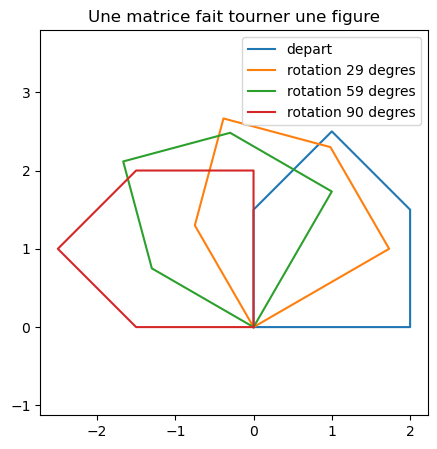

True
[[ 0. -1.]
 [ 1.  0.]]


In [20]:
# votre réponse ici
import matplotlib.pyplot as plt

def rotation(angle):
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s], [s, c]])

maison = np.array([[0, 0], [2, 0], [2, 1.5], [1, 2.5], [0, 1.5], [0, 0]]).T

plt.figure(figsize=(5, 5))
plt.plot(maison[0], maison[1], label="depart")
for angle in (np.pi / 6, np.pi / 3, np.pi / 2):
    image = rotation(angle) @ maison
    plt.plot(image[0], image[1], label=f"rotation {int(np.degrees(angle))} degres")
plt.axis("equal")
plt.legend()
plt.title("Une matrice fait tourner une figure")
plt.show()

gauche = rotation(np.pi / 3) @ rotation(np.pi / 6)
droite = rotation(np.pi / 2)
print(np.allclose(gauche, droite))
print(np.round(droite, 10))

## Exercice 7.1 : déterminant par Gauss

Écrivez `determinant(A)` en reprenant l'élimination de `resoudre`, sans second membre :
multipliez les pivots successifs, et changez le signe à chaque échange de lignes.
Comparez à `np.linalg.det`.

**Résultat attendu :** le déterminant de la matrice de l'étape 1 vaut `-2`, et celui
de `[[1, 2], [2, 4]]` vaut `0`.


In [21]:
# votre réponse ici
def determinant(A):
    n = len(A)
    M = [list(ligne) for ligne in A]
    det = 1.0
    for k in range(n):
        meilleure = max(range(k, n), key=lambda i: abs(M[i][k]))
        if abs(M[meilleure][k]) < 1e-14:
            return 0.0
        if meilleure != k:
            M[k], M[meilleure] = M[meilleure], M[k]
            det = -det
        det = det * M[k][k]
        for i in range(k + 1, n):
            facteur = M[i][k] / M[k][k]
            for j in range(k, n):
                M[i][j] = M[i][j] - facteur * M[k][j]
    return det

A = [[1, 2, 2], [1, 3, -2], [3, 5, 8]]
print(determinant(A), float(np.linalg.det(np.array(A, dtype=float))))
print(determinant([[1, 2], [2, 4]]))

-2.000000000000001 -2.0000000000000013
0.0


## Exercice 8.1 : Hilbert vaincue

Construisez la matrice de Hilbert de taille 12 avec des `Fraction(1, i + j + 1)`, le
second membre `b` comme somme des lignes, pour que la solution soit le vecteur de 1,
puis appelez **votre** fonction `resoudre` de l'étape 4 dessus. Le premier essai échoue
avec « système singulier ». Comprenez pourquoi avant de lire le corrigé, puis corrigez.

**Résultat attendu :** exactement `[1, 1, ..., 1]`, douze fois `Fraction(1, 1)`, là
où `solve` se trompait de 0,7.


In [22]:
# votre réponse ici
from fractions import Fraction

def hilbert_exacte(n):
    return [[Fraction(1, i + j + 1) for j in range(n)] for i in range(n)]

n = 12
H_exacte = hilbert_exacte(n)
b_exact = [sum(ligne) for ligne in H_exacte]

try:
    resoudre(H_exacte, b_exact)
except ValueError as erreur:
    print("premier essai :", erreur)

x_exact = resoudre(H_exacte, b_exact, tolerance=0)
print(x_exact)
print(all(v == 1 for v in x_exact))

premier essai : systeme singulier ou mal pose
[Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1), Fraction(1, 1)]
True


## Exercice 9.1 : l'ordre compte

Écrivez `translation(tx, ty)` et `rotation_h(angle)` qui renvoient des matrices
$3 \times 3$. Appliquez au point $(1, 0)$ la translation de $(3, 1)$ suivie
de la rotation de 90°, puis la rotation suivie de la translation.

**Résultat attendu :** $(-1, 4)$ dans le premier cas, $(3, 2)$ dans le second.
Les deux résultats diffèrent.


In [23]:
# votre réponse ici
def translation(tx, ty):
    return np.array([[1.0, 0.0, tx],
                     [0.0, 1.0, ty],
                     [0.0, 0.0, 1.0]])

def rotation_h(angle):
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s, 0.0],
                     [s, c, 0.0],
                     [0.0, 0.0, 1.0]])

point = np.array([1.0, 0.0, 1.0])
T = translation(3, 1)
R = rotation_h(np.pi / 2)

print(np.round(R @ T @ point, 10))   # translation d'abord, puis rotation
print(np.round(T @ R @ point, 10))   # rotation d'abord, puis translation

[-1.  4.  1.]
[3. 2. 1.]
